# Rozdělení:

[Git - MSM](https://github.com/zcu-sediva/MSM/tree/master/ulohy/uloha1)

| Jméno | Úkol | Text |
| --- | --- | --- |
| Vitalij | 1. | Určení neznámé konstanty `c`|
| Vitalij | 2. | Marginální rozdělení|
| Marek | 3. | Teoretické charakteristiky|
| Marek | 4. | Generování dat |
| Marek | 5. | Odhady z generovaných dat|
| Vitalij | 6. | Porovnání s teoretickými funkcemi |
| Vitalij | 7. | Závislost odhadu na rozsahu výběru |



## 1. Určení neznámé konstanty

- Určete konstantu c tak, aby f(x, y) byla platnou hustotou pravděpodobnosti.

### Řešení 

- konstanta `c` spočítaná ručně. Jednodušší by bylo použít `sympy`.

$$
\begin{align*}
1 &= \int_1^2 \int_1^2 cxy \, dx\,dy \\
  &= c \left[\frac{x^2}{2}\right]_1^2
       \left[\frac{y^2}{2}\right]_1^2 \\
  &= c \cdot \frac{3}{2} \cdot \frac{3}{2}
   = \frac{9c}{4} \\
c &= \boxed{\frac{4}{9}}
\end{align*}
$$

In [32]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [33]:
def density_function(x, y):
    return sp.Piecewise(
        (sp.Rational(4, 9) * x * y, # Funkce
        (x >= 1) & (x <= 2) & (y >= 1) & (y <= 2)), # Doména funkce
        (0, True)) # 0 pro vstupy mimo rozsah

In [ ]:
"""
Calculation of marginal functions, marginal density functions and their visualizations
"""
def marginal_density_functions(f_xy):
    x, y  = sp.symbols("x y", real=True)
    
    f_x = sp.integrate(f_xy(x, y), (y, 1, 2))
    f_y = sp.integrate(f_xy(x, y), (x, 1, 2))
    
    return f_x, f_y

def marginal_distribution_functions(f_xy):
    x, y = sp.symbols("x y", real=True)
    t = sp.symbols("t", real=True)
    
    f_x, f_y = marginal_density_functions(f_xy)
    
    F_x = sp.integrate(f_x.subs(y, t))
    F_y = sp.integrate(f_y.subs(x, t))
    
    return F_x, F_y    

def visualize_marginals(f_x, f_y, F_x, F_y, values):
    x, y = sp.symbols("x y", real=True)
    
    fx = sp.lambdify(x, f_x, "numpy")
    fy = sp.lambdify(y, f_y, "numpy")
    Fx = sp.lambdify(x, F_x, "numpy")
    Fy = sp.lambdify(y, F_y, "numpy")
    
    # Create two plots side by side
    _, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 9))
    
    # Marginal PDFs
    ax1.plot(values, fx(values), label=r"$f_X(x)$")
    ax1.plot(values, fy(values), "--", label=r"$f_Y(y)$")
    ax1.set_title("Marginal Density Functions")
    ax1.set_xlabel("Value")
    ax1.set_ylabel("Density")
    ax1.legend()
    ax1.grid(True)

    # Marginal CDFs
    ax2.plot(values, Fx(values), label=r"$F_X(x)$")
    ax2.plot(values, Fy(values), "--", label=r"$F_Y(y)$")
    ax2.set_title("Marginal Distribution Functions")
    ax2.set_xlabel("Value")
    ax2.set_ylabel("Cumulative Probability")
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

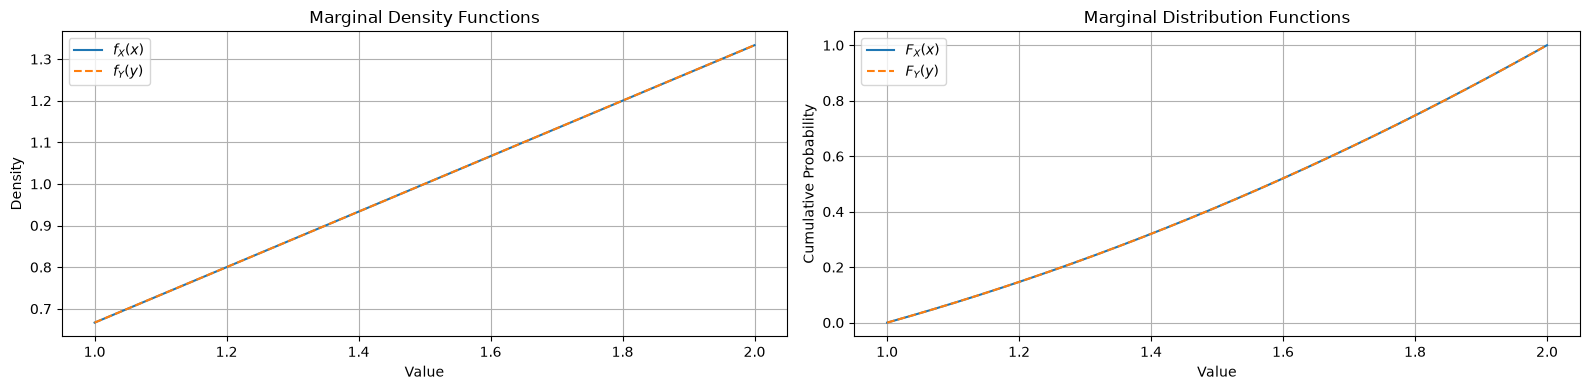

In [35]:
f_x, f_y = marginal_density_functions(density_function)
F_x, F_y  = marginal_distribution_functions(density_function)

# TODO: doplnit generovani dat místo np.linspace(1, 2, 200)
visualize_marginals(f_x, f_y, F_x, F_y, np.linspace(1, 2, 200))